# Example of anomaly detection and analysis using Cam-Su data

In [1]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping
import shap
import warnings
import logging
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler     
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from sklearn.utils import check_array
from tensorflow.keras.losses import mean_squared_error
import seaborn as sns
from sklearn.utils.validation import check_is_fitted
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
from mpl_toolkits.mplot3d import Axes3D
import tensorflow as tf
import math

from tensorflow.keras.layers import Input, Dense,Lambda
from tensorflow.python.keras import backend as K
from tensorflow.python.keras import layers as KL
from tensorflow.python.keras import models as KM

from sklearn.metrics import roc_auc_score
from fbpca import pca
from matplotlib.pyplot import MultipleLocator
from ODBAE_cam import ODBAE
from keras.models import load_model
import matplotlib.ticker as ticker

In [2]:
hidden_activation='relu'
output_activation='sigmoid'
loss=mean_squared_error
optimizer='adam'
epochs=60
batch_size=64
dropout_rate=0.2
l2_regularizer=10e-7
verbose=1
contamination=0.1

In [3]:
X_test_raw = pd.read_csv('Data/Cam_Su_experiment_raw_data.csv')
X_train_raw = pd.read_csv('Data/Cam_Su_control_raw_data.csv')

In [4]:
df_train_value = X_train_raw.iloc[:,4:]
df_test_value = X_test_raw.iloc[:,4:]

In [5]:
normalize=MinMaxScaler()
X_train = pd.DataFrame(normalize.fit_transform(df_train_value),columns=df_train_value.columns)
X_test = pd.DataFrame(normalize.transform(df_test_value),columns=df_test_value.columns)

In [6]:
X_test_gene = pd.DataFrame()
for i in range(X_test.shape[1]):
    X_test_gene[X_test.columns[i]] = X_test[X_test.columns[i]]
X_test_gene['gene_symbol'] = X_test_raw['gene_symbol']
X_test_gene_index = X_test_gene.set_index('gene_symbol')


Text(0, 0.5, 'Body Weight')

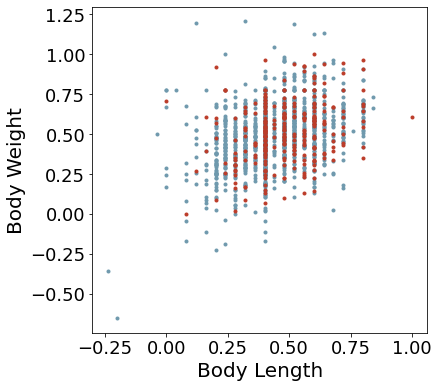

In [7]:
plt.figure(figsize=(6,6))
index1=0
index2=1

plt.plot(X_test[X_test.columns[index1]],X_test[X_test.columns[index2]],'.',color='#6F99ADFF',label='Test')
plt.plot(X_train[X_train.columns[index1]],X_train[X_train.columns[index2]],'.',color='#BC3C29FF',label='Train')
plt.tick_params(labelsize=18)
plt.xlabel(X_test.columns[index1],fontsize=20)
plt.ylabel(X_test.columns[index2],fontsize=20)

In [8]:
def def_loss(y_actual,y_pred):
    data_real_dim = 14
    y_actual_tensor=tf.subtract(y_actual,0,name=None)
    y_actual_tensor=tf.cast(y_actual_tensor, tf.float64)
    y_pred_tensor=tf.subtract(y_pred,0,name=None)
    y_pred_tensor=tf.cast(y_pred_tensor, tf.float64)
    mean_actual_tensor = tf.reduce_mean(y_actual_tensor, axis=0, keepdims=True)
    mean_pred_tensor = tf.reduce_mean(y_pred_tensor, axis=0, keepdims=True)
    cov_actual= tf.matmul(tf.transpose(y_actual_tensor-mean_actual_tensor), y_actual_tensor-mean_actual_tensor)/tf.cast(tf.shape(y_actual_tensor)[0]-1, tf.float64)
    cov_pred= tf.matmul(tf.transpose(y_pred_tensor-mean_pred_tensor), y_pred_tensor-mean_pred_tensor)/tf.cast(tf.shape(y_pred_tensor)[0]-1, tf.float64)
    cov_inv_actual=tf.linalg.inv(cov_actual)
    mashi_loss=tf.reduce_sum(tf.matmul(y_actual_tensor-y_pred_tensor, cov_inv_actual)*(y_actual_tensor-y_pred_tensor))
    eigenvalues_actual, eigenvectors_actual=tf.linalg.eigh(cov_actual)
    eigenvalues_pred, eigenvectors_pred=tf.linalg.eigh(cov_pred)
    eigenvalues_actual_sort_to_control=tf.sort(eigenvalues_actual,direction='DESCENDING')[0:data_real_dim]
    eigenvalues_pred_sort_to_control=tf.sort(eigenvalues_pred,direction='DESCENDING')[0:data_real_dim]
    sqrt_eigenvalues_actual_to_control=tf.sqrt(eigenvalues_actual_sort_to_control, name=None)
    sqrt_eigenvalues_pred_to_control=tf.sqrt(eigenvalues_pred_sort_to_control, name=None)
    
    eigenvalues_actual_sort=tf.sort(eigenvalues_actual,direction='DESCENDING')
    sqrt_eigenvalues_actual=tf.sqrt(eigenvalues_actual_sort, name=None)
    beta_control_list=0.3*sqrt_eigenvalues_actual
    beta_list=sqrt_eigenvalues_actual
    max_beta_control_list=tf.reduce_max(beta_control_list)
    max_beta_control_list_reshape=tf.reshape(max_beta_control_list,[1])
    min_beta_list=tf.reduce_min(beta_list)
    min_beta_list_reshape=tf.reshape(min_beta_list,[1])
    combine_beta_list=tf.concat([max_beta_control_list_reshape,min_beta_list_reshape], axis=0)
    beta_control_value=tf.reduce_min(combine_beta_list)

    eigenvalues_diff=tf.subtract(sqrt_eigenvalues_actual_to_control,sqrt_eigenvalues_pred_to_control,name=None)
    eigenvalues_diff_cast=tf.cast(eigenvalues_diff,tf.float64)
    eigenvalues_diff_control=tf.subtract(eigenvalues_diff_cast,beta_control_value,name=None)
    eigenvalues_diff_control_square=tf.reduce_mean(tf.square(eigenvalues_diff_control))
    
    mean_loss=tf.reduce_mean(tf.square(y_actual_tensor-y_pred_tensor))
    final_loss=0.008*mean_loss+eigenvalues_diff_control_square
    
    return final_loss

In [9]:
autoencoder1 = load_model('Trained_models/autoencoder_Cam_su_new_training_set5',custom_objects={"def_loss":def_loss})

In [10]:
predictions_train = autoencoder1.predict(X_train)
square_errors_train = np.power(X_train - predictions_train, 2)
mse_series_train = pd.Series(np.mean(square_errors_train, axis=1))
X_train_predict = pd.DataFrame(predictions_train,columns = X_train.columns)
mse_train_df =pd.DataFrame(square_errors_train,columns = X_train.columns)

predictions_test = autoencoder1.predict(X_test)
square_errors_test = np.power(X_test - predictions_test, 2)
mse_series_test = pd.Series(np.mean(square_errors_test, axis=1))
X_test_predict = pd.DataFrame(predictions_test,columns = X_test.columns)
mse_test_df =pd.DataFrame(square_errors_test,columns = X_test.columns)

print(np.sum(mse_series_train))
print(np.sum(mse_series_test))

0.5947735593305015
2.863336608846457


In [11]:
abnormal_ratio=0.1  

X_test_ob = pd.DataFrame()
for i in range(X_test.shape[1]):
    X_test_ob[X_test.columns[i]]=X_test[X_test.columns[i]]
X_test_ob['loss']=mse_series_test

X_test_ob_sort = X_test_ob.sort_values(by=['loss'],ascending=False)
X_test_normal =X_test_ob_sort.tail(100)

In [12]:
X_test_explain = pd.DataFrame()
for i in range(X_test.shape[1]):
    X_test_explain[X_test.columns[i]] = X_test[X_test.columns[i]]
X_test_explain['gene_symbol']=X_test_raw['gene_symbol']

X_train_explain = pd.DataFrame()
for i in range(X_train.shape[1]):
    X_train_explain[X_train.columns[i]] = X_train[X_train.columns[i]]
train_category = []
for i in range(X_train_explain.shape[0]):
    train_category.append('None')
X_train_explain['gene_symbol'] = train_category

In [13]:
abnormal_ratio = 0.02
every_parameter_mean = np.mean(X_test,axis=0)
single_parameter_abnormal_index=[]
for i in range(X_test.shape[1]):
    every_parameter_df=pd.DataFrame()
    every_parameter_df[X_test.columns[i]]=X_test[X_test.columns[i]]
    every_parameter_df['normalize_parameter']=np.abs(X_test[X_test.columns[i]]-every_parameter_mean[i])
    every_parameter_df['original_index']=range(X_test.shape[0])
    every_parameter_df_sort=every_parameter_df.sort_values(by=['normalize_parameter'],ascending=False)
    every_parameter_df_sort=every_parameter_df_sort.reset_index(drop=True)
    for j in range(int(abnormal_ratio*X_test.shape[0])):
        single_parameter_abnormal_index.append(every_parameter_df_sort['original_index'][j])
single_parameter_abnormal_index_uniq = list(set(single_parameter_abnormal_index))
print(len(single_parameter_abnormal_index_uniq))
print(len(single_parameter_abnormal_index_uniq)/X_test.shape[0])

234
0.18571428571428572


In [14]:
gene_count = X_test_raw.gene_symbol.value_counts()
singe_abnormal_gene_df = pd.DataFrame()
tmp = []
for i in range(len(single_parameter_abnormal_index_uniq)):
    tmp.append(X_test_raw['gene_symbol'][single_parameter_abnormal_index_uniq[i]])   
singe_abnormal_gene_df['gene_symbol']=tmp

single_gene_count = singe_abnormal_gene_df.gene_symbol.value_counts()
single_gene_list = list(single_gene_count.index)
tmp1=[]
tmp2=[]
for i in range(len(single_gene_list)):
    tmp1.append(single_gene_count[single_gene_list[i]])
    tmp2.append(single_gene_count[single_gene_list[i]]/gene_count[single_gene_list[i]])

singe_abnormal_gene_df_ratio = pd.DataFrame()
singe_abnormal_gene_df_ratio['gene'] = single_gene_list
singe_abnormal_gene_df_ratio['abnormal_number'] = tmp1
singe_abnormal_gene_df_ratio['abnormal_ratio'] = tmp2

print(singe_abnormal_gene_df_ratio)
print(len(single_gene_list))

          gene  abnormal_number  abnormal_ratio
0    Tnfaip8l2                7        1.000000
1          Nmu                7        0.500000
2       Cnot11                5        0.714286
3        Cnih4                5        0.714286
4       Sema7a                5        0.714286
..         ...              ...             ...
114      Kank2                1        0.142857
115       Srms                1        0.142857
116      Rbm18                1        0.166667
117      Wdr86                1        0.142857
118     Pnpla7                1        0.142857

[119 rows x 3 columns]
119


In [15]:
real_single_abnormal_gene = pd.DataFrame()
for i in range(singe_abnormal_gene_df_ratio.shape[0]):
    if singe_abnormal_gene_df_ratio['abnormal_ratio'][i]>=0.4:
        real_single_abnormal_gene = pd.concat([real_single_abnormal_gene,singe_abnormal_gene_df_ratio[i:i+1]], axis=0)
real_single_abnormal_gene = real_single_abnormal_gene.reset_index(drop=True)
print(real_single_abnormal_gene.shape[0])

34


In [16]:
outlier_detection_model = ODBAE(abnormal_rate = len(single_parameter_abnormal_index_uniq)/X_test.shape[0], reconstruction_error_percent=0.5)  # 需要解释前xx个异常点
category_based_anomaly_explanation = outlier_detection_model.outlier_analysis(x_train_raw=X_train_explain,  # 训练集
                                                                 x_test_raw = X_test_explain, 
                                                                autoencoder = autoencoder1,                                    
                                                                batch_parameter = None,
                                                                normalize = False,
                                                                category_parameter = 'gene_symbol')

Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


1 33


Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


2 33


Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


...

31 33


Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


32 33


Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


33 33


In [17]:
category_based_anomaly_explanation = category_based_anomaly_explanation.reset_index(drop=True)
gene_list = category_based_anomaly_explanation.category_col.unique().tolist()

gene_col = []
parameter_col = []
gene_col1 = []
parameter_col1_1 = []
parameter_col1_2 = []
complex_df = pd.DataFrame()
single_df = pd.DataFrame()
for i in range(category_based_anomaly_explanation.shape[0]):
    if len(category_based_anomaly_explanation['explain_result'][i]) == 1:
        gene_col.append(category_based_anomaly_explanation['category_col'][i])
        parameter_col.append(category_based_anomaly_explanation['explain_result'][i][0])
    else:
        gene_col1.append(category_based_anomaly_explanation['category_col'][i])
        parameter_col1_1.append(category_based_anomaly_explanation['explain_result'][i][0])
        parameter_col1_2.append(category_based_anomaly_explanation['explain_result'][i][1])

complex_df['gene_symbol'] = gene_col1
complex_df['ab_parameter1'] = parameter_col1_1
complex_df['ab_parameter2'] = parameter_col1_2

single_df['gene_symbol'] = gene_col
single_df['ab_parameter1'] = parameter_col

complex_df_no_duplicates = complex_df.drop_duplicates()
single_df_no_duplicates = single_df.drop_duplicates()

print(complex_df_no_duplicates.shape[0])
print(single_df_no_duplicates.shape[0])

31
2




`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.



The `vertical` parameter is deprecated; assigning data to `y`.
This will become an error in seaborn v0.14.0; please update your code.



`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.



[None, None, None]

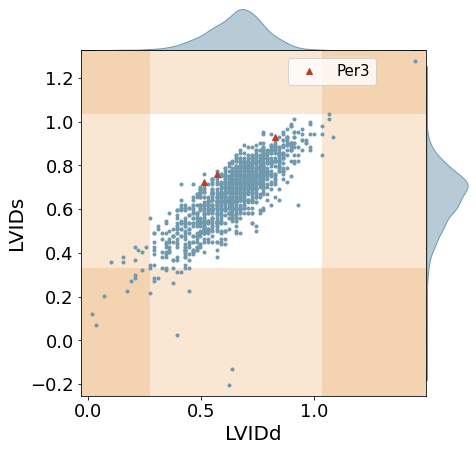

In [22]:
gene='Per3'  
feature1 = 'LVIDd'
feature2 = 'LVIDs'

P1=pd.DataFrame()
P1[feature1]=X_test[feature1]
P1_mean=np.mean(P1[feature1])
P1['deviate']=P1[feature1]-P1_mean
P1['abs_deviate']=np.abs(P1[feature1]-P1_mean)
P1_sort=P1.sort_values(by=['abs_deviate'],ascending=False)
P1_sort_index_list=list(P1_sort.index)
P1_negative=[]
P1_positive=[]
for i in range(int(0.02*X_test.shape[0])):
    if P1_sort['deviate'][P1_sort_index_list[i]]<0:
        P1_negative.append(P1_sort[feature1][P1_sort_index_list[i]])
    if P1_sort['deviate'][P1_sort_index_list[i]]>0:
        P1_positive.append(P1_sort[feature1][P1_sort_index_list[i]])
P1_neg_max=max(P1_negative)
P1_pos_min=min(P1_positive)

P2=pd.DataFrame()
P2[feature2]=X_test[feature2]
P2_mean=np.mean(P2[feature2])
P2['deviate']=P2[feature2]-P2_mean
P2['abs_deviate']=np.abs(P2[feature2]-P2_mean)
P2_sort=P2.sort_values(by=['abs_deviate'],ascending=False)
P2_sort_index_list=list(P2_sort.index)
P2_negative=[]
P2_positive=[]
for i in range(int(0.02*X_test.shape[0])):
    if P2_sort['deviate'][P2_sort_index_list[i]]<0:
        P2_negative.append(P2_sort[feature2][P2_sort_index_list[i]])
    if P2_sort['deviate'][P2_sort_index_list[i]]>0:
        P2_positive.append(P2_sort[feature2][P2_sort_index_list[i]])
P2_neg_max=max(P2_negative)
P2_pos_min=min(P2_positive)

category_based_anomaly_explanation_tmp = pd.DataFrame()
for i in range(category_based_anomaly_explanation.shape[1]):
    category_based_anomaly_explanation_tmp[category_based_anomaly_explanation.columns[i]]=category_based_anomaly_explanation[category_based_anomaly_explanation.columns[i]]
category_based_anomaly_explanation_tmp['index']=category_based_anomaly_explanation_tmp['original_index']
category_based_anomaly_explanation_tmp=category_based_anomaly_explanation_tmp.set_index('category_col')
ob_data_index=category_based_anomaly_explanation_tmp.loc[gene]
ob_data_index_list=ob_data_index.original_index.tolist()
ob_gene_data=pd.DataFrame()
gene_drop=pd.DataFrame()
for i in range(X_test.shape[0]):
    if i in ob_data_index_list:
        ob_gene_data=pd.concat([ob_gene_data, X_test[i:i+1]], axis = 0)
    else:
        gene_drop=pd.concat([gene_drop, X_test[i:i+1]], axis = 0)


fig=plt.figure(figsize=(6,6))
ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8])  
ax2 = fig.add_axes([0.1, 0.9, 0.8, 0.1])  
ax3 = fig.add_axes([0.9, 0.1, 0.1, 0.8])
ax1.plot(gene_drop[feature1],gene_drop[feature2],'.',color='#6F99ADFF') 
ax1.plot(ob_gene_data[feature1],ob_gene_data[feature2],'^',color='#BC3C29FF',label=gene)
sns.kdeplot(data=X_test, x=feature1, shade=True, alpha=0.5, ax=ax2, legend=False,color='#6F99ADFF')
sns.kdeplot(data=X_test, x=feature2, shade=True, alpha=0.5, vertical=True, ax=ax3, legend=False,color='#6F99ADFF')

xmin=min(X_test[feature1])-0.05
xmax=max(X_test[feature1])+0.05
ymin=min(X_test[feature2])-0.05
ymax=max(X_test[feature2])+0.05
ax1.axhspan(ymin, P2_neg_max, facecolor='#E18727FF', alpha=0.2)
ax1.axhspan(P2_pos_min, ymax, facecolor='#E18727FF', alpha=0.2)
ax1.axvspan(xmin, P1_neg_max, facecolor='#E18727FF', alpha=0.2)
ax1.axvspan(P1_pos_min, xmax, facecolor='#E18727FF', alpha=0.2)

ax1.set_xlim(xmin,xmax)
ax1.set_ylim(ymin,ymax)
ax1.tick_params(labelsize=18)
ax1.set_xlabel(feature1,fontsize=20)
ax1.set_ylabel(feature2,fontsize=20)
ax1.legend(prop=dict(size=15),bbox_to_anchor=(0.6, 0.9),loc=3, borderaxespad=0)

ax2.set_ylim(bottom=-0.01)
ax2.set_xlabel(None)
ax2.set_ylabel(None)
ax2.set_xticks([])
ax2.set_yticks([])
[ax2.spines[x].set_visible(False) for x in ['right', 'top', 'left']]

ax3.set_xlim(left=-0.01)
ax3.set_xlabel(None)
ax3.set_ylabel(None)
ax3.set_xticks([])
ax3.set_yticks([])
[ax3.spines[x].set_visible(False) for x in ['right', 'top', 'bottom']]